In [1]:
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

<div style="height: 15px;"></div>

# 4. Testing the Method on Aether (5/4)

The previous experiments on smooth Earth and dynamic Fire revealed repeated timing patterns in two contrasting compositions, both written in 4/4.

Now, I want to test it on Aether, becouse there is a different musical meter — 5/4.

My goal is to test whether the same mathematical method can detect an underlying periodic structure without changing the algorithm or its parameters.

The detected timing will be evaluated against my manual editing in DaVinci Resolve.

In [2]:
# Loading the original Aether audio file
aether_path = Path("data/aether.wav")

if not aether_path.exists():
    raise FileNotFoundError(
        f"Audio file not found: {aether_path.resolve()}"
    )

sample_rate_aether, audio_aether = wavfile.read(aether_path)

print("Sample rate:", sample_rate_aether)
print("Shape:", audio_aether.shape)
print(
    "Duration:",
    len(audio_aether) / sample_rate_aether,
    "seconds"
)

Sample rate: 48000
Shape: (17240264, 2)
Duration: 359.17216666666667 seconds


C:\Users\Radev\AppData\Local\Temp\ipykernel_13676\313270301.py:9: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate_aether, audio_aether = wavfile.read(aether_path)


<div style="height: 15px;"></div>

### 4.1 Representing the Aether Audio Signal

As with Earth and Fire, the stereo channels are combined into a mono signal and the amplitude is normalized to the interval [-1, 1].

The same representation is used to keep the mathematical analysis consistent across all three compositions.

In [3]:
# Combine stereo channels
audio_mono_aether = audio_aether.mean(axis=1).astype(np.float64)

# Normalize amplitude
x_aether = audio_mono_aether / np.max(np.abs(audio_mono_aether))

# Time axis
t_aether = np.arange(len(x_aether)) / sample_rate_aether

print(f"Number of samples: {len(x_aether)}")
print(f"Sampling rate: {sample_rate_aether} Hz")
print(f"Duration: {t_aether[-1]:.2f} seconds")

Number of samples: 17240264
Sampling rate: 48000 Hz
Duration: 359.17 seconds


<div style="height: 15px;"></div>

### 4.2 Visualizing the Aether Signal

The complete Aether recording is visualized as an amplitude function of time.

A reduced number of samples is used only for plotting. The original signal remains unchanged for the mathematical analysis.

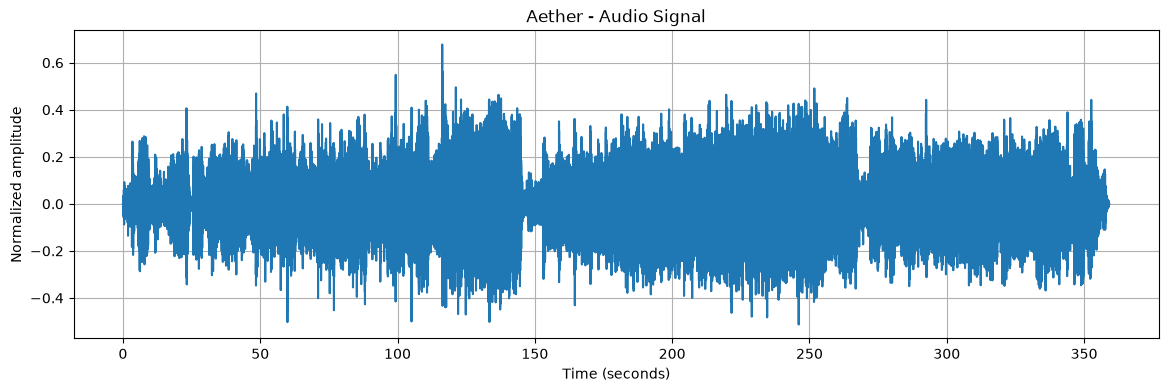

In [4]:
# Fewer points only for visualization
target_points = 100_000
step_aether = max(1, len(x_aether) // target_points)

plt.figure(figsize=(14, 4))

plt.plot(
    t_aether[::step_aether],
    x_aether[::step_aether]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("Aether - Audio Signal")
plt.grid()

plt.show()

<div style="height: 15px;"></div>

### 4.3 Detecting the Hidden Pulse

The same mean-square signal analysis and time-shift similarity method used for Earth and Fire is applied to Aether, without changing the parameters.

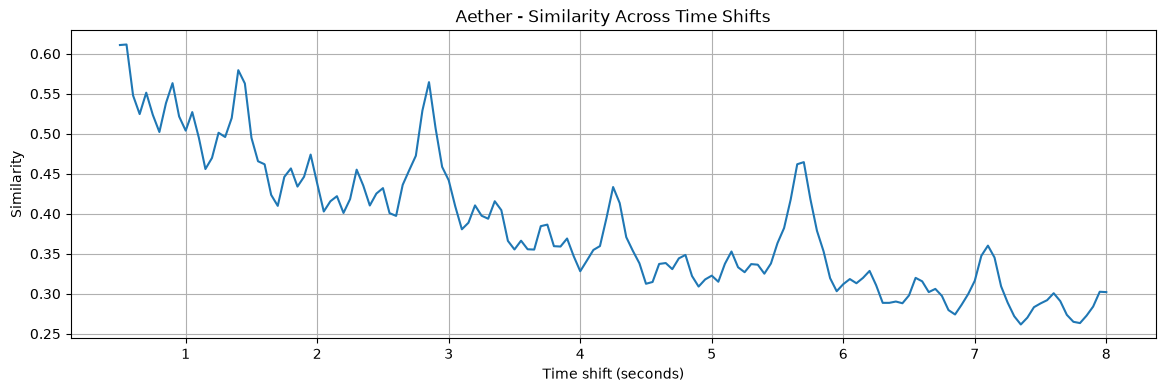

In [5]:
# Calculate local mean-square signal level
window_seconds = 0.05
window_size_aether = int(window_seconds * sample_rate_aether)

usable_samples_aether = (
    len(x_aether) // window_size_aether
) * window_size_aether

aether_windows = x_aether[:usable_samples_aether].reshape(
    -1, window_size_aether
)

local_energy_aether = np.mean(aether_windows ** 2, axis=1)
energy_time_aether = np.arange(len(local_energy_aether)) * window_seconds

# Compare the signal with time-shifted copies
energy_centered_aether = (
    local_energy_aether - np.mean(local_energy_aether)
)

min_lag_seconds = 0.5
max_lag_seconds = 8.0

min_lag_aether = int(round(min_lag_seconds / window_seconds))
max_lag_aether = int(round(max_lag_seconds / window_seconds))

lags_aether = np.arange(min_lag_aether, max_lag_aether + 1)
similarities_aether = []

for lag in lags_aether:
    a = energy_centered_aether[:-lag]
    b = energy_centered_aether[lag:]

    similarity = np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b)
    )

    similarities_aether.append(similarity)

lag_times_aether = lags_aether * window_seconds
similarities_aether = np.array(similarities_aether)

# Visualize time-shift similarity
plt.figure(figsize=(14, 4))
plt.plot(lag_times_aether, similarities_aether)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Aether - Similarity Across Time Shifts")
plt.grid()

plt.show()

<div style="height: 15px;"></div>

### 4.4 Detecting Candidate Periods

As with Earth and Fire, local similarity maxima above 1.5 seconds are identified and ranked to find the strongest candidate repetition periods.

Top Aether candidate periods:
2.85 s (similarity = 0.565)
1.95 s (similarity = 0.474)
5.70 s (similarity = 0.464)
1.80 s (similarity = 0.457)
2.30 s (similarity = 0.455)
4.25 s (similarity = 0.433)
2.50 s (similarity = 0.432)
2.15 s (similarity = 0.422)



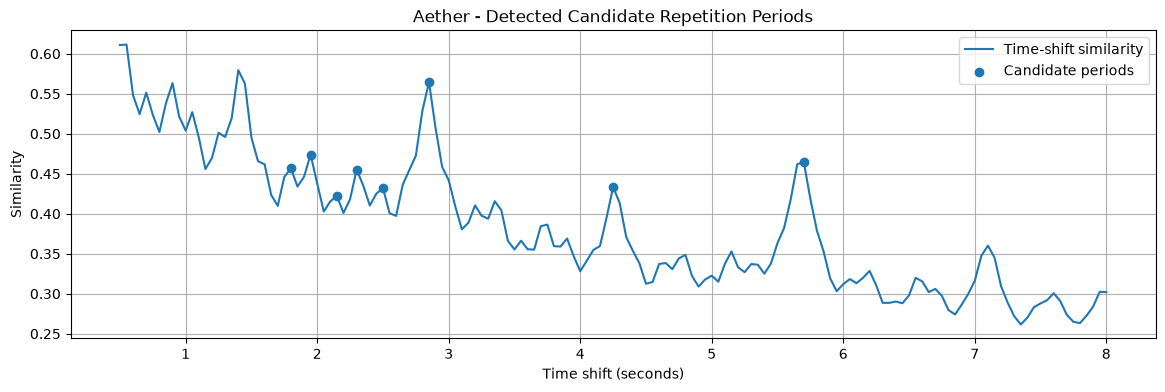

In [6]:
# Finding local maxima using the same criterion as Earth and Fire
candidate_min_seconds = 1.5
candidate_indices_aether = []

for i in range(1, len(similarities_aether) - 1):
    is_local_maximum = (
        similarities_aether[i] > similarities_aether[i - 1]
        and similarities_aether[i] >= similarities_aether[i + 1]
    )

    is_long_enough = (
        lag_times_aether[i] >= candidate_min_seconds
    )

    if is_local_maximum and is_long_enough:
        candidate_indices_aether.append(i)

candidate_indices_aether = np.array(
    candidate_indices_aether, dtype=int
)

# Rank candidates by similarity
sorted_indices_aether = candidate_indices_aether[
    np.argsort(similarities_aether[candidate_indices_aether])[::-1]
]

top_candidates_aether = sorted_indices_aether[:8]

print("Top Aether candidate periods:")

for i in top_candidates_aether:
    print(
        f"{lag_times_aether[i]:.2f} s "
        f"(similarity = {similarities_aether[i]:.3f})"
    )

print()

# Plot detected candidate periods
plt.figure(figsize=(14, 4))

plt.plot(
    lag_times_aether,
    similarities_aether,
    label="Time-shift similarity"
)

plt.scatter(
    lag_times_aether[top_candidates_aether],
    similarities_aether[top_candidates_aether],
    label="Candidate periods",
    zorder=3
)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Aether - Detected Candidate Repetition Periods")
plt.grid()
plt.legend()

plt.show()

<div style="height: 15px;"></div>

### 4.5 Determining the Phase

The strongest detected period is used to calculate the average cycle across the complete Aether recording and identify its phase.

Detected period: 2.85 s
Detected phase: 2.00 s



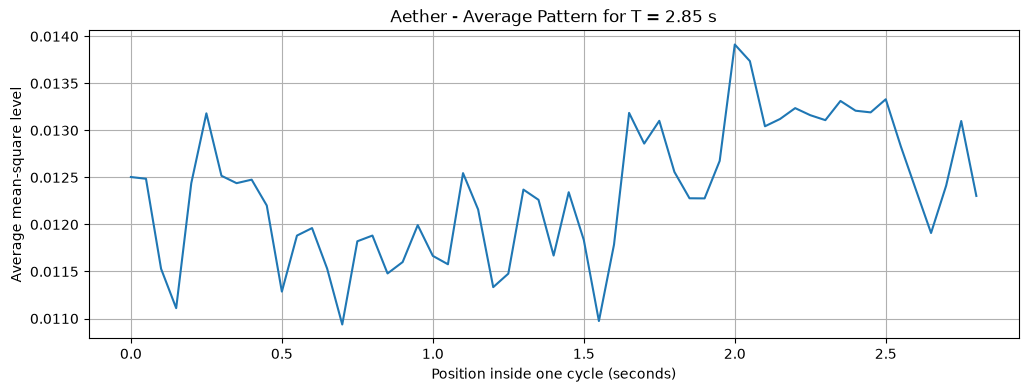

In [7]:
# Strongest detected period
best_period_aether = lag_times_aether[top_candidates_aether[0]]

# Convert the period to 50 ms windows
period_bins_aether = int(round(best_period_aether / window_seconds))

# Keep complete cycles
usable_values_aether = (
    len(local_energy_aether) // period_bins_aether
) * period_bins_aether

cycle_matrix_aether = local_energy_aether[
    :usable_values_aether
].reshape(-1, period_bins_aether)

# Average the cycles
mean_cycle_aether = np.mean(cycle_matrix_aether, axis=0)
phase_time_aether = np.arange(period_bins_aether) * window_seconds

# Find the strongest position inside the average cycle
best_phase_index_aether = np.argmax(mean_cycle_aether)
best_phase_aether = phase_time_aether[best_phase_index_aether]

print(f"Detected period: {best_period_aether:.2f} s")
print(f"Detected phase: {best_phase_aether:.2f} s")

print()

plt.figure(figsize=(12, 4))
plt.plot(phase_time_aether, mean_cycle_aether)

plt.xlabel("Position inside one cycle (seconds)")
plt.ylabel("Average mean-square level")
plt.title(f"Aether - Average Pattern for T = {best_period_aether:.2f} s")
plt.grid()
plt.show()

<div style="height: 15px;"></div>

### 4.6 Candidate Editing Points

The detected period and phase are used to generate candidate editing points for a random one-minute section (03:30–04:30).

The timing remains anchored to the beginning of the complete recording.

In [8]:
# Convert seconds to DaVinci Resolve timecode (24 fps)
def seconds_to_timecode(seconds, fps=24, start_hour=1):
    total_frames = int(round(seconds * fps))

    frames = total_frames % fps
    total_seconds = total_frames // fps

    seconds_part = total_seconds % 60
    minutes = (total_seconds // 60) % 60
    hours = start_hour + total_seconds // 3600

    return f"{hours:02d}:{minutes:02d}:{seconds_part:02d}:{frames:02d}"


# Selected validation section: 03:30–04:30
test_start_aether = 210.0
test_end_aether = 270.0

# Generate the timing grid from the beginning of the song
all_candidate_times_aether = np.arange(
    best_phase_aether,
    t_aether[-1],
    best_period_aether
)

# Keep only candidates in the selected section
candidate_times_aether = all_candidate_times_aether[
    (all_candidate_times_aether >= test_start_aether)
    & (all_candidate_times_aether < test_end_aether)
]

print("Aether candidate edit points (210–270 s):")

for candidate in candidate_times_aether:
    print(
        f"{candidate:7.2f} s -> "
        f"{seconds_to_timecode(candidate)}"
    )

Aether candidate edit points (210–270 s):
 210.05 s -> 01:03:30:01
 212.90 s -> 01:03:32:22
 215.75 s -> 01:03:35:18
 218.60 s -> 01:03:38:14
 221.45 s -> 01:03:41:11
 224.30 s -> 01:03:44:07
 227.15 s -> 01:03:47:04
 230.00 s -> 01:03:50:00
 232.85 s -> 01:03:52:20
 235.70 s -> 01:03:55:17
 238.55 s -> 01:03:58:13
 241.40 s -> 01:04:01:10
 244.25 s -> 01:04:04:06
 247.10 s -> 01:04:07:02
 249.95 s -> 01:04:09:23
 252.80 s -> 01:04:12:19
 255.65 s -> 01:04:15:16
 258.50 s -> 01:04:18:12
 261.35 s -> 01:04:21:08
 264.20 s -> 01:04:24:05
 267.05 s -> 01:04:27:01
 269.90 s -> 01:04:29:22


<div style="height: 15px;"></div>

### 4.7 Practical Validation in DaVinci Resolve

The method detected a repetition period of **2.85 seconds** in Aether, using the same algorithm as Earth and Fire.

I tested the generated editing points against my original timeline between **03:30 and 04:30**.

The initial timing showed a small offset of approximately **3–7 frames**. This way of cutting, was not nice for the eyes and the natural transition. <br> After shifting the entire generated grid by **6 frames**, the cuts aligned closely with the original editing rhythm. <br>The remaining differences were generally around **1–3 frames**, which may reflect my artistic decisions rather than incorrect musical timing.

This is a positive result for a third composition, this time in **5/4**. The method identified a useful repeated timing structure without changing its parameters, although manual phase adjustment was still necessary.

The detected period does not by itself prove the musical meter or identify a uniquely correct editing point.


#### Visual Validation Examples

The following screenshots compare the detected timing grid with my original manual editing in DaVinci Resolve.

<img src="figures/aether_origin_full_view.png" width="950">

*Figure 7. Overview of the original manual edit and generated timing grid.*

<div style="height: 25px;"></div>

<img src="figures/aether_origin_close_view.png" width="950">

*Figure 8. Closer comparison of the editing points before phase adjustment.*

<div style="height: 25px;"></div>

<img src="figures/aether_manual_offset_corection.png" width="950">

*Figure 9. Comparison after shifting the generated timing grid by approximately 6 frames.*